#Linear Regression

In [63]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

##Create Dataset

In [64]:
data = {
    'Study_Hours': [2, 3, 4, 5, 6, 7, 8, 2, 4, 6, 8, 9, 3, 7, 10],
    'Attendance': [65, 70, 75, 80, 85, 90, 95, 60, 72, 88, 92, 96, 68, 86, 98],
    'Assignment_Score': [55, 60, 65, 70, 75, 80, 85, 50, 62, 78, 88, 92, 58, 82, 95],
    'Previous_Score': [50, 55, 60, 65, 70, 75, 80, 48, 58, 72, 85, 88, 52, 78, 90],
    'Sleep_Hours': [6, 7, 7, 8, 7, 8, 8, 6, 7, 8, 7, 8, 6, 7, 9],
    'Exam_Score': [35, 42, 50, 58, 65, 73, 82, 30, 47, 68, 85, 90, 39, 76, 96]
}

data = pd.DataFrame(data)

data

,Study_Hours,Attendance,Assignment_Score,Previous_Score,Sleep_Hours,Exam_Score
0,2,65,55,50,6,35
1,3,70,60,55,7,42
2,4,75,65,60,7,50
3,5,80,70,65,8,58
4,6,85,75,70,7,65
5,7,90,80,75,8,73
6,8,95,85,80,8,82
7,2,60,50,48,6,30
8,4,72,62,58,7,47
9,6,88,78,72,8,68


##Check Dataset

In [65]:
print(data.info())

print("\nMissing Values:")
print(data.isnull().sum())

print("\nDuplicate Rows:")
print(data.duplicated().sum())

print("\nStatistical Description:")
print(data.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Study_Hours       15 non-null     int64
 1   Attendance        15 non-null     int64
 2   Assignment_Score  15 non-null     int64
 3   Previous_Score    15 non-null     int64
 4   Sleep_Hours       15 non-null     int64
 5   Exam_Score        15 non-null     int64
dtypes: int64(6)
memory usage: 852.0 bytes
None

Missing Values:
Study_Hours         0
Attendance          0
Assignment_Score    0
Previous_Score      0
Sleep_Hours         0
Exam_Score          0
dtype: int64

Duplicate Rows:
0

Statistical Description:
       Study_Hours  Attendance  Assignment_Score  Previous_Score  Sleep_Hours  \
count    15.000000   15.000000         15.000000       15.000000    15.000000   
mean      5.600000   81.333333         73.000000       68.400000     7.266667   
std       2.557901   12.262991         1

##Visualize Dataset

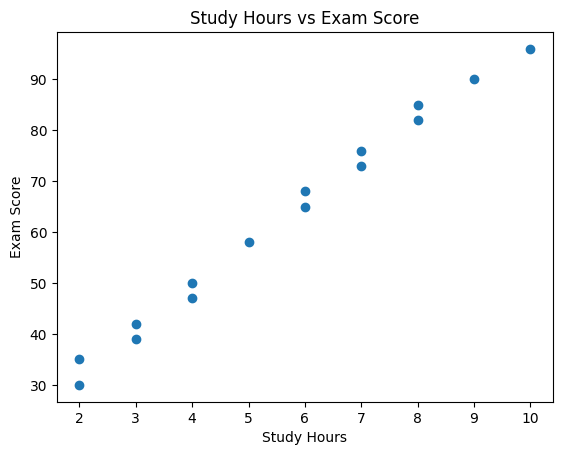

In [66]:
plt.scatter(data['Study_Hours'], data['Exam_Score'])

plt.xlabel('Study Hours')
plt.ylabel('Exam Score')
plt.title('Study Hours vs Exam Score')

plt.show()

##Separate Input and Output

In [67]:
X = data.drop('Exam_Score', axis=1).values

y = data['Exam_Score'].values

##Split Dataset into Training and Testing Data

In [68]:
np.random.seed(42)

indices = np.random.permutation(len(X))

train_size = int(0.8 * len(X))

train_indices = indices[:train_size]
test_indices = indices[train_size:]

X_train = X[train_indices]
X_test = X[test_indices]

y_train = y[train_indices]
y_test = y[test_indices]

print("Training Data:", len(X_train))
print("Testing Data:", len(X_test))

Training Data: 12
Testing Data: 3


##Feature scaling

In [69]:
mean = X_train.mean(axis=0)
std = X_train.std(axis=0)

X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

##Create Linear Regression Class

In [70]:
class LinearRegression:

    def __init__(self, learning_rate=0.01, iterations=10000):
        self.learning_rate = learning_rate
        self.iterations = iterations
        self.m = None
        self.c = None

    def fit(self, X, y):

        n = len(X)

        self.m = np.zeros(X.shape[1])
        self.c = 0

        for i in range(self.iterations):

            y_pred = np.dot(X, self.m) + self.c

            dm = (2/n) * np.dot(X.T, (y_pred - y))
            dc = (2/n) * np.sum(y_pred - y)

            self.m -= self.learning_rate * dm
            self.c -= self.learning_rate * dc

    def predict(self, X):

        return np.dot(X, self.m) + self.c

##Train the Model

In [71]:
model = LinearRegression()

model.fit(X_train, y_train)

print("Model Training Completed")
print("Weights:", model.m)
print("Intercept:", model.c)

Model Training Completed
Weights: [ 5.58419831  0.82761626  7.65634316  7.19680315 -0.15870463]
Intercept: 63.083333333333165


##Make Predictions

In [72]:
y_pred = model.predict(X_test)

result = pd.DataFrame({
    'Actual Score': y_test,
    'Predicted Score': np.round(y_pred, 2)
})

result

,Actual Score,Predicted Score
0,39,39.53
1,58,57.42
2,82,80.72


##Evaluate the Model

In [73]:
mse = np.mean((y_test - y_pred) ** 2)

ss_total = np.sum((y_test - np.mean(y_test)) ** 2)
ss_residual = np.sum((y_test - y_pred) ** 2)

r2 = 1 - (ss_residual / ss_total)

print("Mean Squared Error:", round(mse, 2))
print("R2 Score:", round(r2, 4))

Mean Squared Error: 0.75
R2 Score: 0.9976


##Visualize Predictions

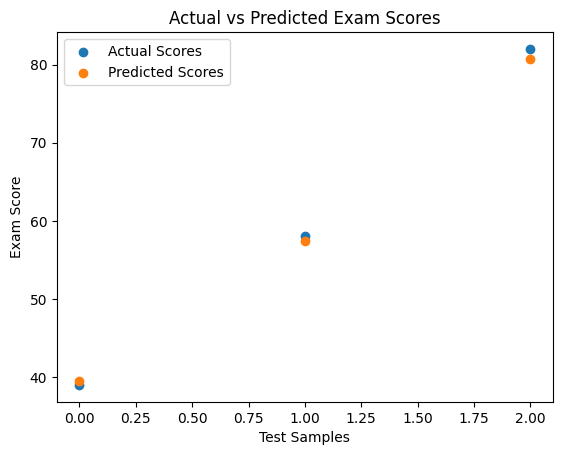

In [74]:
plt.scatter(range(len(y_test)), y_test, label='Actual Scores')

plt.scatter(range(len(y_pred)), y_pred, label='Predicted Scores')

plt.xlabel('Test Samples')
plt.ylabel('Exam Score')
plt.title('Actual vs Predicted Exam Scores')

plt.legend()
plt.show()

#Logistic Regression

##Dataset

In [75]:
data = {
    'Study_Hours': [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 3, 5, 7, 9, 11],
    'Attendance': [40, 45, 50, 55, 60, 65, 70, 75, 80, 90, 48, 62, 78, 85, 95],
    'Assignment_Score': [30, 35, 40, 45, 50, 55, 65, 70, 75, 90, 38, 58, 68, 82, 95],
    'Previous_Score': [25, 30, 35, 40, 45, 50, 60, 65, 70, 85, 32, 48, 62, 78, 90],
    'Sleep_Hours': [5, 5, 6, 6, 6, 7, 7, 7, 8, 8, 6, 7, 7, 8, 9],
    'Pass': [0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 0, 1, 1, 1, 1]
}

data = pd.DataFrame(data)

data

,Study_Hours,Attendance,Assignment_Score,Previous_Score,Sleep_Hours,Pass
0,1,40,30,25,5,0
1,2,45,35,30,5,0
2,3,50,40,35,6,0
3,4,55,45,40,6,0
4,5,60,50,45,6,0
5,6,65,55,50,7,1
6,7,70,65,60,7,1
7,8,75,70,65,7,1
8,9,80,75,70,8,1
9,10,90,90,85,8,1


##Check Dataset

In [76]:
print(data.info())

print("\nMissing Values:")
print(data.isnull().sum())

print("\nDuplicate Rows:")
print(data.duplicated().sum())

print("\nStatistical Description:")
print(data.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 6 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Study_Hours       15 non-null     int64
 1   Attendance        15 non-null     int64
 2   Assignment_Score  15 non-null     int64
 3   Previous_Score    15 non-null     int64
 4   Sleep_Hours       15 non-null     int64
 5   Pass              15 non-null     int64
dtypes: int64(6)
memory usage: 852.0 bytes
None

Missing Values:
Study_Hours         0
Attendance          0
Assignment_Score    0
Previous_Score      0
Sleep_Hours         0
Pass                0
dtype: int64

Duplicate Rows:
0

Statistical Description:
       Study_Hours  Attendance  Assignment_Score  Previous_Score  Sleep_Hours  \
count    15.000000   15.000000         15.000000       15.000000    15.000000   
mean      6.000000   66.533333         59.733333       54.333333     6.800000   
std       3.047247   17.074905         2

##Visualize Dataset

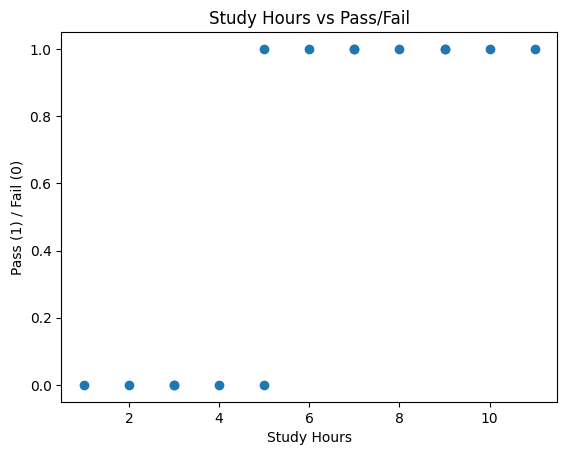

In [77]:
plt.scatter(data['Study_Hours'], data['Pass'])

plt.xlabel('Study Hours')
plt.ylabel('Pass (1) / Fail (0)')
plt.title('Study Hours vs Pass/Fail')

plt.show()

##Separate Input and Output

In [78]:
X = data.drop('Pass', axis=1).values
y = data['Pass'].values

##Split Dataset into Training and Testing Data

In [79]:
np.random.seed(42)

indices = np.random.permutation(len(X))

train_size = int(0.8 * len(X))

train_indices = indices[:train_size]
test_indices = indices[train_size:]

X_train = X[train_indices]
X_test = X[test_indices]

y_train = y[train_indices]
y_test = y[test_indices]

print("Training Data:", len(X_train))
print("Testing Data:", len(X_test))

Training Data: 12
Testing Data: 3


##Feature Scaling

In [80]:
mean = X_train.mean(axis=0)
std = X_train.std(axis=0)

X_train = (X_train - mean) / std
X_test = (X_test - mean) / std

###

## Logistic Regression Class

In [81]:
class LogisticRegression:

    def __init__(self, learning_rate=0.01, iterations=10000):
        self.learning_rate = learning_rate
        self.iterations = iterations
        self.weights = None
        self.bias = 0

    def sigmoid(self, z):
        z = np.clip(z, -500, 500)
        return 1 / (1 + np.exp(-z))

    def fit(self, X, y):

        n_samples, n_features = X.shape

        self.weights = np.zeros(n_features)
        self.bias = 0

        for i in range(self.iterations):

            linear_model = np.dot(X, self.weights) + self.bias

            y_pred = self.sigmoid(linear_model)

            dw = (1 / n_samples) * np.dot(X.T, (y_pred - y))
            db = (1 / n_samples) * np.sum(y_pred - y)

            self.weights -= self.learning_rate * dw
            self.bias -= self.learning_rate * db

    def predict(self, X):

        linear_model = np.dot(X, self.weights) + self.bias

        probabilities = self.sigmoid(linear_model)

        return np.where(probabilities >= 0.5, 1, 0)

##Train the Model

In [82]:
model = LogisticRegression()

model.fit(X_train, y_train)

print("Model Training Completed")
print("Weights:", model.weights)
print("Bias:", model.bias)

Model Training Completed
Weights: [1.15724841 1.23620759 1.50444265 0.98647202 2.88115635]
Bias: 2.2678896412639276


##Make Predictions

In [83]:
y_pred = model.predict(X_test)

result = pd.DataFrame({
    'Actual Result': y_test,
    'Predicted Result': y_pred
})

result

,Actual Result,Predicted Result
0,1,1
1,0,0
2,1,1


##Evaluate the Model

In [84]:
accuracy = np.mean(y_test == y_pred) * 100

print("Accuracy:", accuracy, "%")

Accuracy: 100.0 %


##Display Pass/Fail Results

In [85]:
for i in range(len(y_pred)):

    if y_pred[i] == 1:
        print("Student", i + 1, ": Pass")
    else:
        print("Student", i + 1, ": Fail")

Student 1 : Pass
Student 2 : Fail
Student 3 : Pass
